# DAG Consistency Analysis
Measures three things for any set of DSPredict dags runs:

1. **Intra-model R→I consistency** — how faithfully does each model translate its reasoning DAG into its implementation DAG?
2. **Code-following-plan** — how well does the generated code cover the implementation nodes?
3. **Inter-model plan divergence** — on the same competition, how different are each model's plans?

### How to add a new model
In the **Configuration** cell below, add an entry to `MODEL_CONFIGS`:
```python
"my-new-model": {
    "suffix": "_my_new_model_dags.json",   # file suffix for per-task files
    "color":  "#9C27B0",
}
```
All plots and tables will automatically include it.


In [1]:
import json, re, os
from collections import defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

plt.rcParams.update({
    "figure.dpi": 120,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})
print("Imports OK.")
from rouge_score import rouge_scorer


Imports OK.


## Configuration
Edit `TASK_DIR` and `MODEL_CONFIGS` to point at your run directory and model files.


In [2]:
# ── Edit these ────────────────────────────────────────────────────────────────
TASK_DIR = Path(".")      # directory containing per-task *_dags.json files

MODEL_CONFIGS = {
    "gpt-4o-mini": {
        "suffix": "_gpt_4o_mini_dags.json",
        "color":  "#FF9800",
    },
    "gpt-5.1": {
        "suffix": "_gpt_5_1_dags.json",
        "color":  "#2196F3",
    },
    "claude-sonnet-4-5": {
        "suffix": "_claude_sonnet_4_5_dags.json",
        "color":  "#4CAF50",
    },
}

STOP_WORDS = {
    "the","a","an","and","or","to","of","in","for","with","on","from","using",
    "use","all","each","by","into","as","at","is","are","be","its","this","that",
    "if","any","no","data","model","step","based","new","make","get","set","run",
    "then","also","both","only","when","will","has","have","not","their",
}
# ──────────────────────────────────────────────────────────────────────────────
print("Config loaded. Models:", list(MODEL_CONFIGS.keys()))


Config loaded. Models: ['gpt-4o-mini', 'gpt-5.1', 'claude-sonnet-4-5']


## DAG & Keyword Extraction Helpers

In [3]:
def extract_dags(content):
    """Extract DAG objects from an assistant message.
    Handles fenced ```json blocks (gpt-4o-mini, Claude) and
    raw inline JSON objects starting with {"dag_type": ...} (gpt-5.1).
    """
    candidates = []
    for block in re.findall(r"```json\s*(.*?)\s*```", content, re.DOTALL):
        candidates.append(block.strip())
    for m in re.finditer(r'\{"dag_type"', content):
        depth, i = 0, m.start()
        for j in range(i, min(i + 10000, len(content))):
            if content[j] == "{": depth += 1
            elif content[j] == "}": 
                depth -= 1
                if depth == 0:
                    candidates.append(content[i:j+1])
                    break
    dags = []
    seen = set()
    for block in candidates:
        try:
            obj = json.loads(block)
            if isinstance(obj, dict) and "dag_type" in obj and "nodes" in obj:
                key = obj["dag_type"] + str(len(obj["nodes"]))
                if key not in seen:
                    dags.append(obj)
                    seen.add(key)
        except (json.JSONDecodeError, ValueError):
            pass
    return dags


def node_labels(dag):
    return [n.get("label", "").lower() for n in dag.get("nodes", [])]


def keywords(labels):
    """Bag of meaningful words from a list of node labels."""
    words = set()
    for lbl in labels:
        for w in re.findall(r"[a-z][a-z0-9]+", lbl):
            if w not in STOP_WORDS and len(w) > 2:
                words.add(w)
    return words


def jaccard(a, b):
    if not a and not b: return 1.0
    return len(a & b) / len(a | b)


def challenge_from_row(row):
    """Reliably extract competition name from a result row."""
    ch = row.get("challenge")
    if ch: return ch
    sid = row.get("sample_id", "") or ""
    if "_" in sid:
        inner = sid.split("_", 1)[1]
        comp = inner.rsplit("_", 1)[0]
        if comp: return comp
    return None


print("Helpers defined.")

def rouge_scores(plan_a: list, plan_b: list) -> dict:
    """ROUGE-1/2/L F1 between two ordered lists of node labels."""
    scorer = rouge_scorer.RougeScorer(["rouge1","rouge2","rougeL"], use_stemmer=True)
    a = " ".join(plan_a) if plan_a else ""
    b = " ".join(plan_b) if plan_b else ""
    if not a or not b:
        return {"rouge1":0.0,"rouge2":0.0,"rougeL":0.0}
    s = scorer.score(a, b)
    return {"rouge1":s["rouge1"].fmeasure,"rouge2":s["rouge2"].fmeasure,"rougeL":s["rougeL"].fmeasure}


Helpers defined.


## Load Data
Reads every `*_dags.json` per-task file and extracts DAGs + code from trajectories.


In [4]:
records = []   # one dict per (model, competition) run

for model, cfg in MODEL_CONFIGS.items():
    suffix = cfg["suffix"]
    found  = 0
    for fname in sorted(os.listdir(TASK_DIR)):
        if not fname.endswith(suffix):
            continue
        path = TASK_DIR / fname
        try:
            item = json.load(open(path))
        except Exception:
            continue

        if not isinstance(item, dict):
            continue

        comp = fname.replace(suffix, "")
        # strip trailing index if present (e.g. _28 -> competition name)
        comp_clean = re.sub(r"_\d+$", "", comp)

        traj       = item.get("trajectory", [])
        first_asst = next((t for t in traj if isinstance(t, dict) and t.get("role") == "assistant"), None)
        if not first_asst:
            continue

        dags        = extract_dags(first_asst.get("content", ""))
        r_dags      = [d for d in dags if d.get("dag_type") == "reasoning"]
        i_dags      = [d for d in dags if "implementation" in d.get("dag_type", "")]

        has_dag     = bool(r_dags) and bool(i_dags)

        # Outcome
        status  = (item.get("metrics", {}).get("kaggle_submission", {})
                       .get("details", {}).get("status", "") or "")
        outcome = ("complete"   if "COMPLETE" in status else
                   "error"      if "ERROR"    in status else "no_submit")

        # All code from trajectory
        all_code = " ".join(
            c for t in traj if isinstance(t, dict) and t.get("role") == "assistant"
            for c in re.findall(r"<python>(.*?)</python>", t.get("content", ""), re.DOTALL)
        ).lower()

        rec = {
            "model":        model,
            "comp":         comp_clean,
            "fname":        fname,
            "outcome":      outcome,
            "has_dag":      has_dag,
            "all_code":     all_code,
            "total_turns":  item.get("total_turns"),
            "exec_min":     (item.get("execution_time") or 0) / 60,
        }

        if has_dag:
            r_dag = r_dags[0]
            i_dag = i_dags[0]
            r_lbls = node_labels(r_dag)
            i_lbls = node_labels(i_dag)
            r_kw   = keywords(r_lbls)
            i_kw   = keywords(i_lbls)

            ri_jaccard = jaccard(r_kw, i_kw)
            ri_overlap = len(r_kw & i_kw) / max(1, len(r_kw))
            node_delta = len(i_lbls) - len(r_lbls)

            # Code coverage: fraction of impl nodes whose keywords appear anywhere in code
            node_hits = [
                bool(keywords([lbl]) & set(re.findall(r"[a-z][a-z0-9]+", all_code)))
                for lbl in i_lbls
            ]
            code_cov = sum(node_hits) / max(1, len(node_hits))
            miss_pos = ([i/len(node_hits) for i,h in enumerate(node_hits) if not h] or [None])[0]

            rec.update({
                "r_nodes":      len(r_lbls),
                "i_nodes":      len(i_lbls),
                "node_delta":   node_delta,
                "r_kw_n":       len(r_kw),
                "i_kw_n":       len(i_kw),
                "ri_jaccard":   ri_jaccard,
                "ri_rouge1":   rouge_scores(r_lbls, i_lbls)["rouge1"],
                "ri_rouge2":   rouge_scores(r_lbls, i_lbls)["rouge2"],
                "ri_rougeL":   rouge_scores(r_lbls, i_lbls)["rougeL"],
                "ri_overlap":   ri_overlap,
                "code_cov":     code_cov,
                "first_miss":   miss_pos,
                "r_kw":         r_kw,
                "i_kw":         i_kw,
                "r_lbls":       r_lbls,
                "i_lbls":       i_lbls,
            })

        records.append(rec)
        found += 1

    print(f"  {model}: {found} files, {sum(1 for r in records if r['model']==model and r['has_dag'])} with DAGs")

df     = pd.DataFrame([{k:v for k,v in r.items() if k not in ('r_kw','i_kw','r_lbls','i_lbls','all_code')} for r in records])
df_dag = df[df["has_dag"]].copy()
print(f"\nTotal records: {len(df)},  with DAGs: {len(df_dag)}")
display(df_dag.groupby(["model","outcome"]).size().unstack(fill_value=0))


  gpt-4o-mini: 54 files, 54 with DAGs
  gpt-5.1: 53 files, 53 with DAGs
  claude-sonnet-4-5: 35 files, 35 with DAGs

Total records: 142,  with DAGs: 142


outcome,complete,error,no_submit
model,,,
claude-sonnet-4-5,18,8,9
gpt-4o-mini,5,4,45
gpt-5.1,28,12,13


## 1 · Intra-model R→I Consistency
How faithfully does each model translate its *reasoning* plan into an *implementation* plan?

| Metric | What it means |
|---|---|
| **R→I Jaccard** | Overlap of keyword sets — higher = more verbatim copy, lower = genuine refinement |
| **R→I overlap** | % of reasoning keywords preserved in implementation |
| **Node Δ** | `len(impl) − len(reasoning)` — padding vs compression |
| **Code cov** | Fraction of implementation nodes whose keywords appear in the generated code |
| **First miss pos** | Where in the plan the first uncovered node falls (0=start, 1=end) |


In [5]:
summary_rows = []
for model in MODEL_CONFIGS:
    sub = df_dag[df_dag["model"] == model]
    for outcome in ["complete", "error", "no_submit", "ALL"]:
        s = sub if outcome == "ALL" else sub[sub["outcome"] == outcome]
        if len(s) == 0: continue
        summary_rows.append({
            "Model":          model,
            "Outcome":        outcome,
            "n":              len(s),
            "R nodes":        s["r_nodes"].mean(),
            "I nodes":        s["i_nodes"].mean(),
            "Node Δ":         s["node_delta"].mean(),
            "R→I Jaccard":    s["ri_jaccard"].mean(),
            "R→I overlap":    s["ri_overlap"].mean(),
            "Code cov":       s["code_cov"].mean(),
            "First miss pos": s["first_miss"].dropna().mean() if s["first_miss"].notna().any() else float("nan"),
        })

sum_df = pd.DataFrame(summary_rows)
for col in ["R nodes","I nodes","Node Δ","R→I Jaccard","R→I overlap","Code cov","First miss pos"]:
    sum_df[col] = sum_df[col].round(3)

display(sum_df.set_index(["Model","Outcome"]))


n  R nodes  I nodes  Node Δ  R→I Jaccard  \
Model             Outcome                                                
gpt-4o-mini       complete    5    6.200    7.600   1.400        0.392   
                  error       4    6.500    7.250   0.750        0.349   
                  no_submit  45    6.622    8.044   1.422        0.381   
                  ALL        54    6.574    7.944   1.370        0.380   
gpt-5.1           complete   28    6.250    6.250   0.000        0.236   
                  error      12    6.250    6.250   0.000        0.223   
                  no_submit  13    7.231    7.231   0.000        0.254   
                  ALL        53    6.491    6.491   0.000        0.238   
claude-sonnet-4-5 complete   18    5.722    5.722   0.000        0.230   
                  error       8    5.750    6.125   0.375        0.258   
                  no_submit   9    6.333    6.556   0.222        0.276   
                  ALL        35    5.886    6.029   0.143        0.248   

                             R→I overlap  Code cov  First miss pos  
Model             Outcome                                           
gpt-4o-mini       complete         0.574     0.975           0.375  
                  error            0.575     1.000             NaN  
                  no_submit        0.627     0.957           0.471  
                  ALL              0.618     0.962           0.463  
gpt-5.1           complete         0.437     1.000             NaN  
                  error            0.430     1.000             NaN  
                  no_submit        0.480     0.923           0.000  
                  ALL              0.446     0.981           0.000  
claude-sonnet-4-5 complete         0.464     1.000             NaN  
                  error            0.486     1.000             NaN  
                  no_submit        0.505     0.984           0.714  
                  ALL              0.479     0.996           0.714

### Visualisations

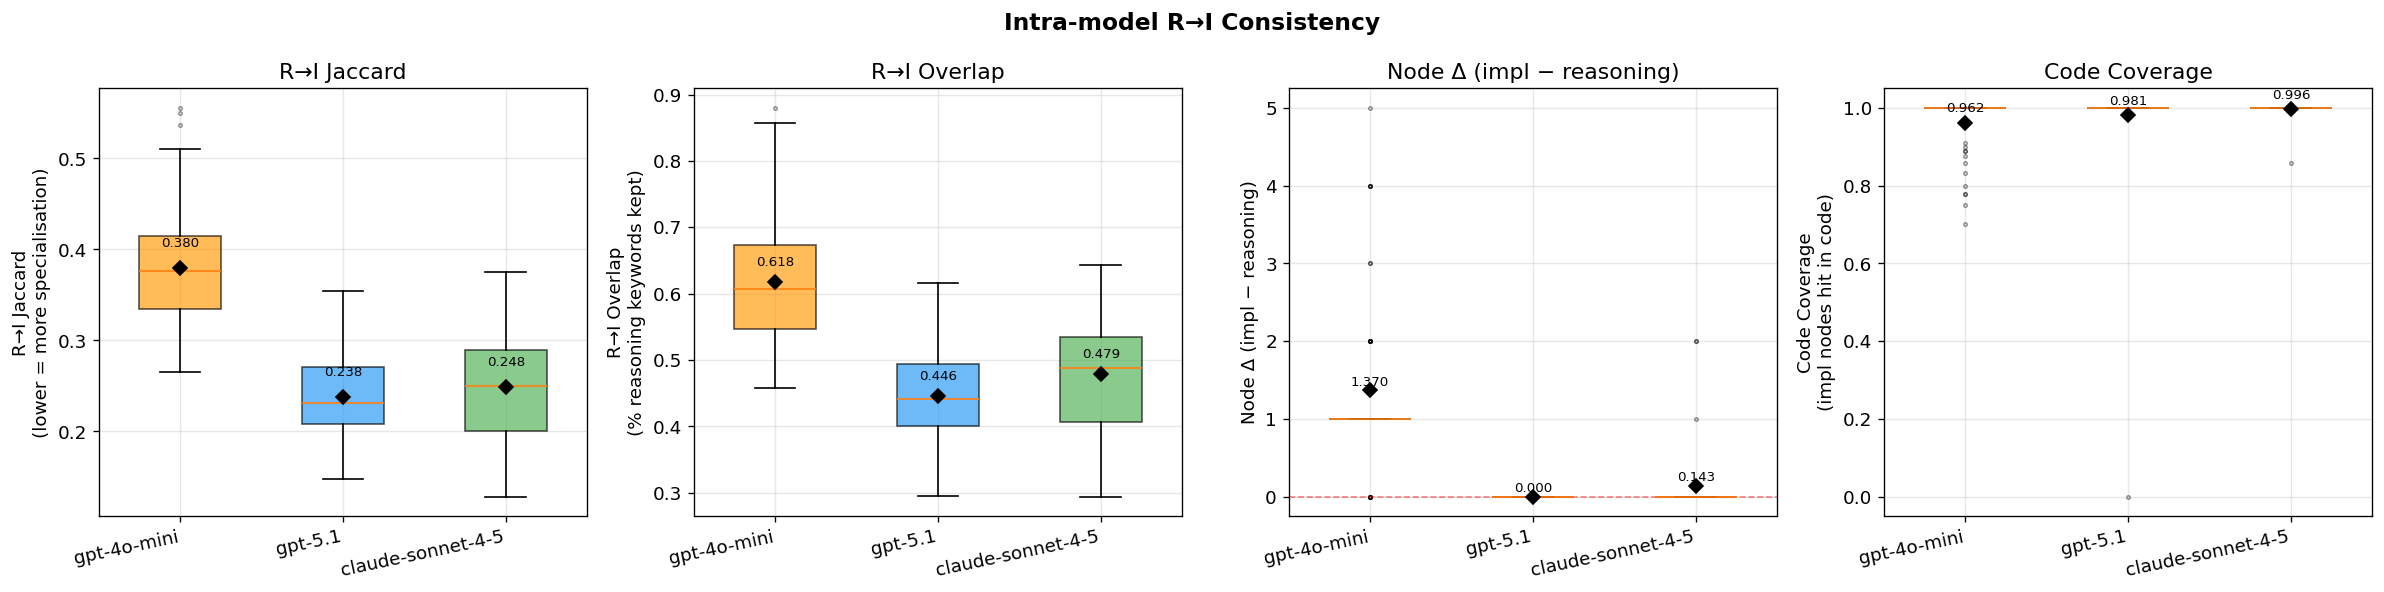

Saved dag_ri_consistency.png


In [6]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle("Intra-model R→I Consistency", fontsize=14, fontweight="bold")

metrics = [
    ("ri_jaccard",  "R→I Jaccard\n(lower = more specialisation)", False),
    ("ri_overlap",  "R→I Overlap\n(% reasoning keywords kept)",   False),
    ("node_delta",  "Node Δ (impl − reasoning)",                   True),
    ("code_cov",    "Code Coverage\n(impl nodes hit in code)",     False),
]

for ax, (col, ylabel, show_zero) in zip(axes, metrics):
    model_vals = {m: df_dag[df_dag["model"]==m][col].dropna().values
                  for m in MODEL_CONFIGS}
    positions  = np.arange(len(MODEL_CONFIGS))
    colors     = [MODEL_CONFIGS[m]["color"] for m in MODEL_CONFIGS]

    bp = ax.boxplot(
        [model_vals[m] for m in MODEL_CONFIGS],
        positions=positions, patch_artist=True,
        widths=0.5, showfliers=True,
        flierprops=dict(marker=".", alpha=0.4, markersize=4),
    )
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.65)

    # overlay means
    for pos, m in zip(positions, MODEL_CONFIGS):
        mean = np.mean(model_vals[m]) if len(model_vals[m]) else 0
        ax.plot(pos, mean, "D", color="black", markersize=6, zorder=5)
        ax.text(pos, mean + 0.02, f"{mean:.3f}", ha="center", va="bottom", fontsize=8)

    if show_zero:
        ax.axhline(0, color="red", lw=1, ls="--", alpha=0.5)

    ax.set_xticks(positions)
    ax.set_xticklabels(list(MODEL_CONFIGS.keys()), rotation=12, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(ylabel.split("\n")[0])

plt.tight_layout()
plt.savefig(TASK_DIR / "dag_ri_consistency.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved dag_ri_consistency.png")


## ROUGE Syntactic Similarity (R→I)
ROUGE treats each DAG plan as a document (node labels joined in order).

| Metric | Measures | Key signal |
|---|---|---|
| **ROUGE-1** | Unigram F1 | Same *words* used |
| **ROUGE-2** | Bigram F1 | Same *two-word phrases* (local step order) |
| **ROUGE-L** | LCS F1 | Same *sequential ordering* of steps |

High ROUGE-1 but low ROUGE-L → same vocabulary, reordered execution (improvisation). High ROUGE-L → model follows its reasoning plan in sequence.


Model                    ROUGE-1   ROUGE-2   ROUGE-L  Interpretation
--------------------------------------------------------------------------------
gpt-4o-mini                0.622     0.262     0.497  Boilerplate / highly generic plan
gpt-5.1                    0.476     0.125     0.327  Specialised plan, moderate order adherence
claude-sonnet-4-5          0.457     0.087     0.337  Specialised plan, moderate order adherence


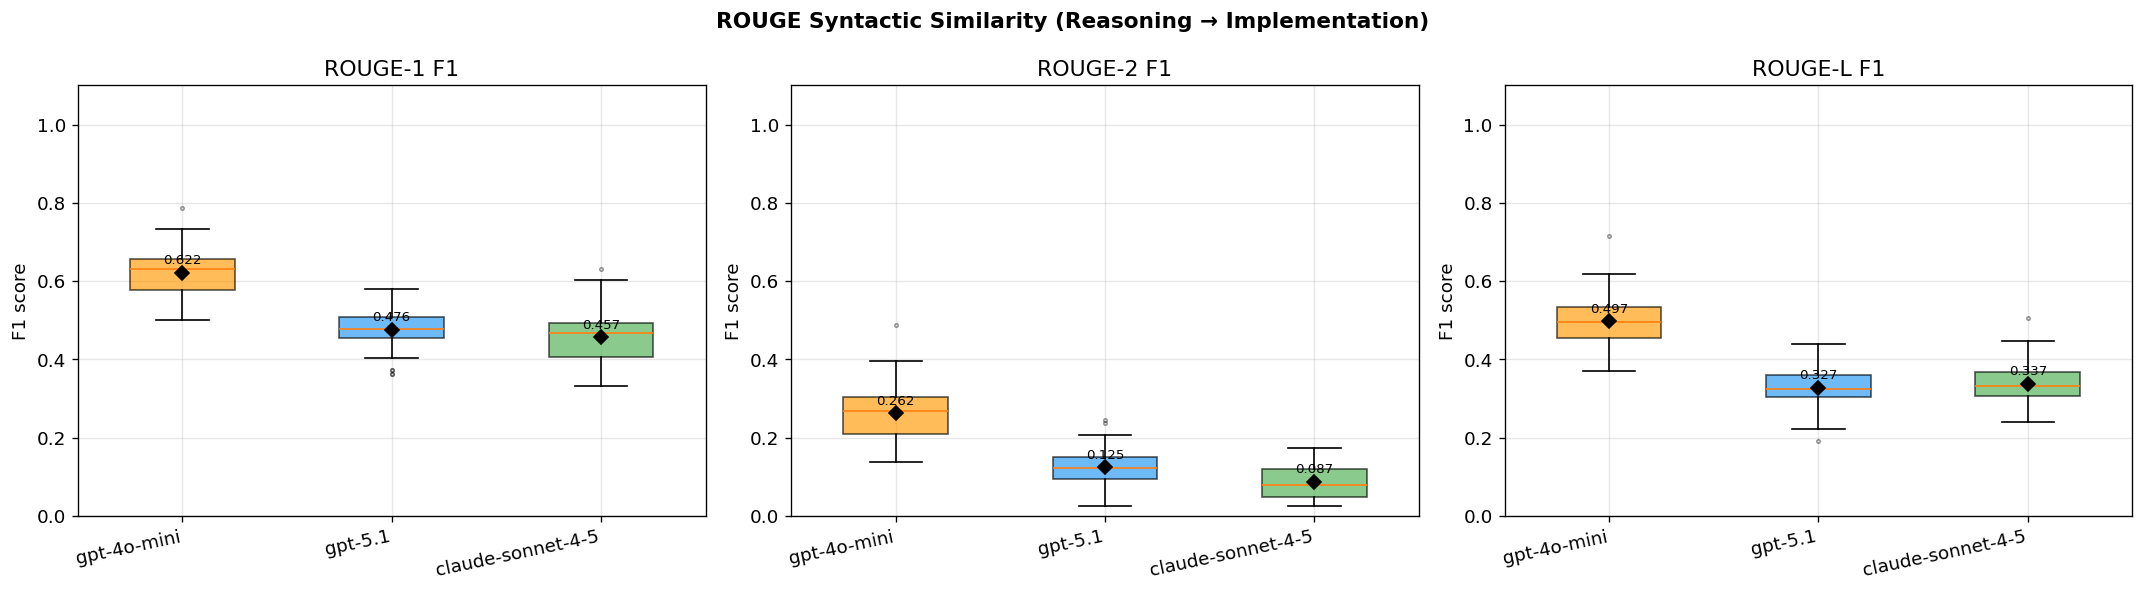

Saved dag_rouge_similarity.png


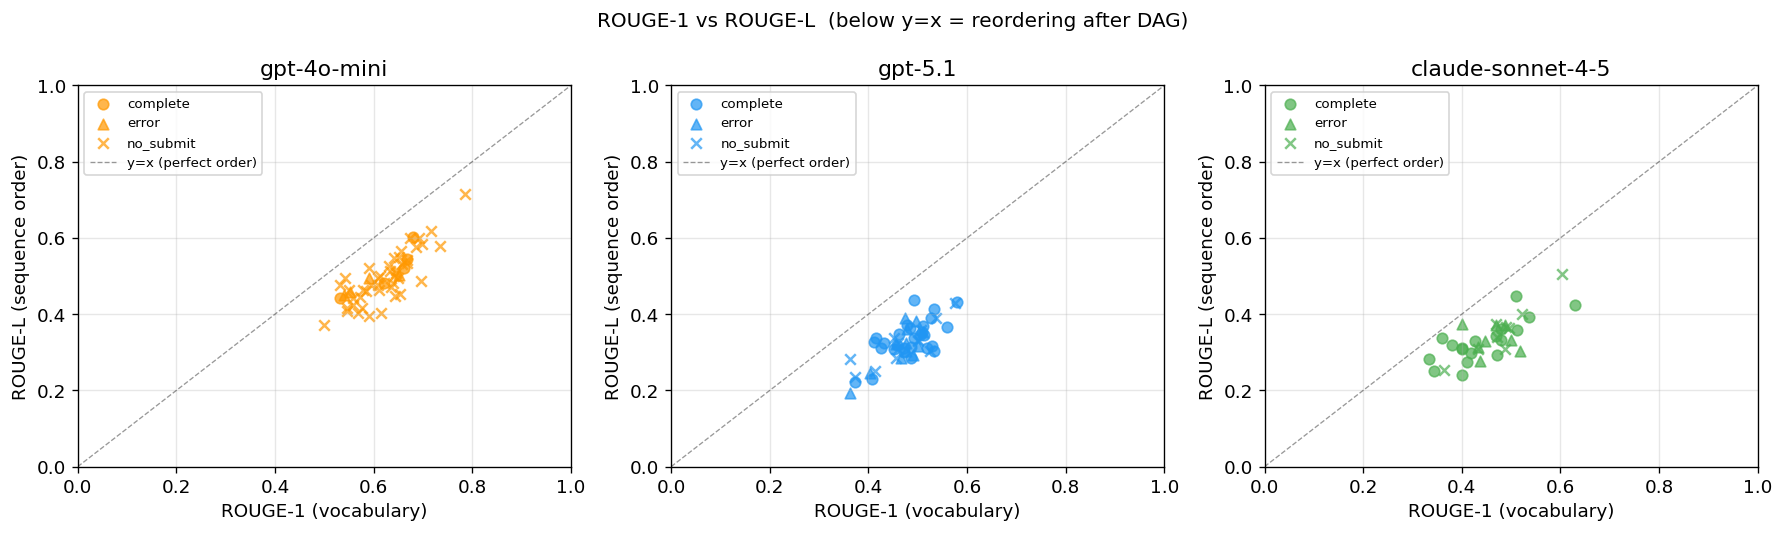

Saved dag_rouge_scatter.png


In [7]:
rouge_metrics = ["ri_rouge1", "ri_rouge2", "ri_rougeL"]
rouge_labels  = {
    "ri_rouge1": "ROUGE-1 F1\n(unigram overlap)",
    "ri_rouge2": "ROUGE-2 F1\n(bigram / phrase overlap)",
    "ri_rougeL": "ROUGE-L F1\n(sequence order / LCS)",
}

# Summary table
print("%-22s %9s %9s %9s  %s" % ("Model","ROUGE-1","ROUGE-2","ROUGE-L","Interpretation"))
print("-" * 80)
for model in MODEL_CONFIGS:
    sub = df_dag[df_dag["model"] == model]
    r1  = sub["ri_rouge1"].mean()
    r2  = sub["ri_rouge2"].mean()
    rL  = sub["ri_rougeL"].mean()
    gap = r1 - rL
    if r1 > 0.60:
        interp = "Boilerplate / highly generic plan"
    elif gap > 0.20:
        interp = "Same vocab, different order (reactive improvisation)"
    elif rL > 0.40:
        interp = "Follows own plan sequentially"
    else:
        interp = "Specialised plan, moderate order adherence"
    print("%-22s %9.3f %9.3f %9.3f  %s" % (model, r1, r2, rL, interp))

# Box plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("ROUGE Syntactic Similarity (Reasoning \u2192 Implementation)",
             fontsize=13, fontweight="bold")
for ax, metric in zip(axes, rouge_metrics):
    model_vals = {m: df_dag[df_dag["model"]==m][metric].dropna().values for m in MODEL_CONFIGS}
    positions  = np.arange(len(MODEL_CONFIGS))
    colors     = [MODEL_CONFIGS[m]["color"] for m in MODEL_CONFIGS]
    bp = ax.boxplot([model_vals[m] for m in MODEL_CONFIGS],
                    positions=positions, patch_artist=True, widths=0.5, showfliers=True,
                    flierprops=dict(marker=".", alpha=0.4, markersize=4))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color); patch.set_alpha(0.65)
    for pos, m in zip(positions, MODEL_CONFIGS):
        mean = np.nanmean(model_vals[m]) if len(model_vals[m]) else 0
        ax.plot(pos, mean, "D", color="black", markersize=6, zorder=5)
        ax.text(pos, mean + 0.015, f"{mean:.3f}", ha="center", va="bottom", fontsize=8)
    ax.set_xticks(positions)
    ax.set_xticklabels(list(MODEL_CONFIGS.keys()), rotation=12, ha="right")
    ax.set_ylabel("F1 score")
    ax.set_title(rouge_labels[metric].split("\n")[0])
    ax.set_ylim(0, 1.1)
plt.tight_layout()
plt.savefig(TASK_DIR / "dag_rouge_similarity.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved dag_rouge_similarity.png")

# ROUGE-1 vs ROUGE-L scatter
n_models = len(MODEL_CONFIGS)
fig, axes = plt.subplots(1, n_models, figsize=(5*n_models, 4.5))
if n_models == 1:
    axes = [axes]
fig.suptitle("ROUGE-1 vs ROUGE-L  (below y=x = reordering after DAG)", fontsize=12)
outcome_markers = {"complete": "o", "error": "^", "no_submit": "x"}
for ax, model in zip(axes, MODEL_CONFIGS):
    sub   = df_dag[df_dag["model"]==model].dropna(subset=["ri_rouge1","ri_rougeL"])
    color = MODEL_CONFIGS[model]["color"]
    for outcome, marker in outcome_markers.items():
        s = sub[sub["outcome"]==outcome]
        ax.scatter(s["ri_rouge1"], s["ri_rougeL"],
                   marker=marker, color=color, alpha=0.7, s=40, label=outcome)
    ax.plot([0,1],[0,1],"k--",lw=0.8,alpha=0.4,label="y=x (perfect order)")
    ax.set_xlabel("ROUGE-1 (vocabulary)"); ax.set_ylabel("ROUGE-L (sequence order)")
    ax.set_title(model); ax.set_xlim(0,1); ax.set_ylim(0,1); ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(TASK_DIR / "dag_rouge_scatter.png", bbox_inches="tight", dpi=150)
plt.show()
print("Saved dag_rouge_scatter.png")


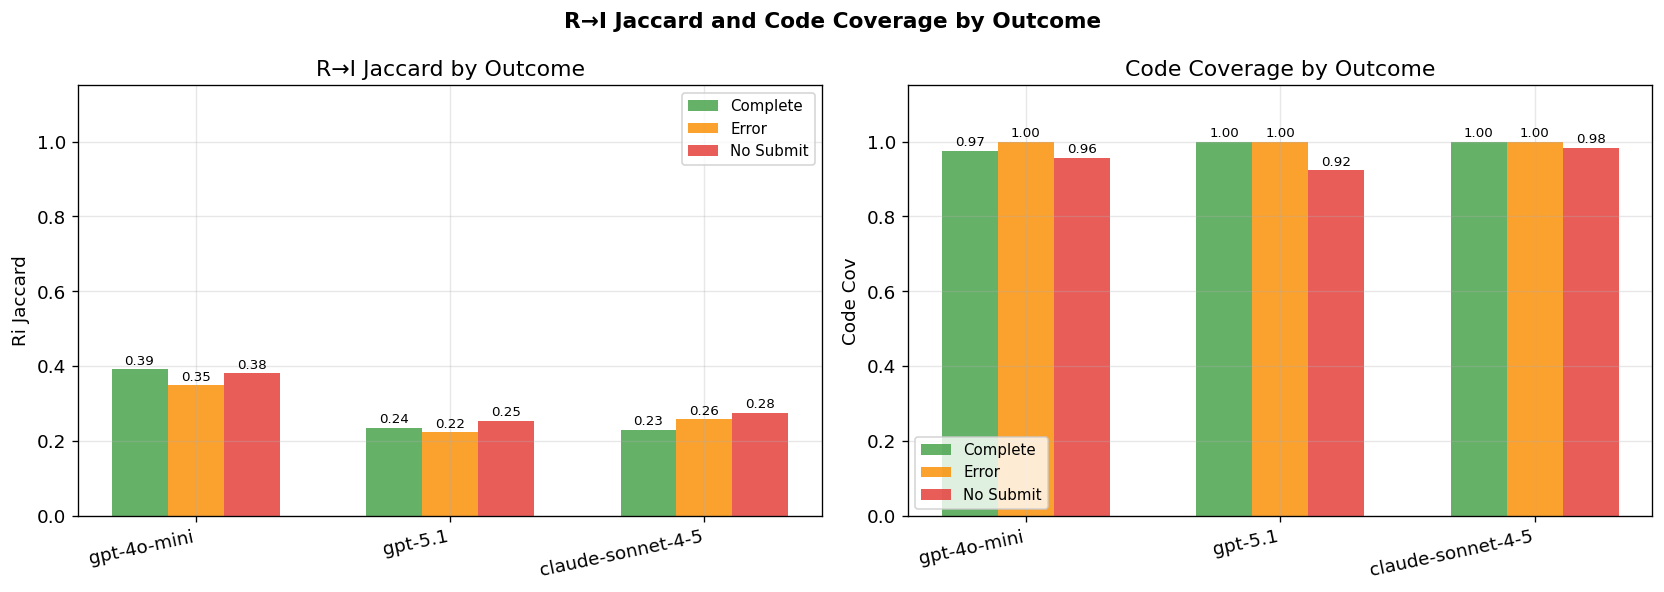

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("R→I Jaccard and Code Coverage by Outcome", fontsize=13, fontweight="bold")

outcome_colors = {"complete": "#43A047", "error": "#FB8C00", "no_submit": "#E53935"}
outcome_order  = ["complete", "error", "no_submit"]

for ax, col in zip(axes, ["ri_jaccard", "code_cov"]):
    model_list = list(MODEL_CONFIGS.keys())
    n_models   = len(model_list)
    n_outcomes = len(outcome_order)
    x = np.arange(n_models)
    w = 0.22

    for oi, outcome in enumerate(outcome_order):
        vals = []
        for m in model_list:
            sub = df_dag[(df_dag["model"]==m) & (df_dag["outcome"]==outcome)][col].dropna()
            vals.append(sub.mean() if len(sub) else 0)
        offset = (oi - 1) * w
        bars = ax.bar(x + offset, vals, w, label=outcome.replace("_"," ").title(),
                      color=outcome_colors[outcome], alpha=0.82)
        for bar, v in zip(bars, vals):
            if v > 0.01:
                ax.text(bar.get_x()+bar.get_width()/2, v+0.005,
                        f"{v:.2f}", ha="center", va="bottom", fontsize=8)

    ax.set_xticks(x)
    ax.set_xticklabels(model_list, rotation=12, ha="right")
    ax.set_ylabel(col.replace("_"," ").title())
    ax.set_title(f"{'R→I Jaccard' if col=='ri_jaccard' else 'Code Coverage'} by Outcome")
    ax.legend(fontsize=9)
    ax.set_ylim(0, 1.15)

plt.tight_layout()
plt.savefig(TASK_DIR / "dag_outcome_breakdown.png", bbox_inches="tight", dpi=150)
plt.show()


## 2 · What Changes Between Reasoning and Implementation?
For each model, what concepts are **added** in the implementation that weren't in the reasoning, and what gets **dropped**?
A model that adds generic boilerplate (`encode`, `csv`, `forest`) is not specialising.
A model that adds competition-specific terms (`catboost`, `acoustic`, `temporal`) is genuinely planning.


In [9]:
from collections import Counter

for model in MODEL_CONFIGS:
    recs = [r for r in records if r["model"]==model and r["has_dag"]]
    all_added   = Counter()
    all_dropped = Counter()
    for r in recs:
        r_kw, i_kw = r["r_kw"], r["i_kw"]
        for w in i_kw - r_kw: all_added[w]   += 1
        for w in r_kw - i_kw: all_dropped[w] += 1

    print(f"\n── {model} (n={len(recs)}) ──")
    print(f"  Top 15 ADDED in impl (not in reasoning):")
    print("   ", [f"{w}({c})" for w,c in all_added.most_common(15)])
    print(f"  Top 15 DROPPED from reasoning:")
    print("   ", [f"{w}({c})" for w,c in all_dropped.most_common(15)])



── gpt-4o-mini (n=54) ──
  Top 15 ADDED in impl (not in reasoning):
    ['csv(40)', 'check(39)', 'encode(35)', 'features(35)', 'save(33)', 'categorical(32)', 'scale(30)', 'summarize(28)', 'random(27)', 'forest(27)', 'dataset(24)', 'numerical(23)', 'variables(23)', 'them(22)', 'read(21)']
  Top 15 DROPPED from reasoning:
    ['explore(50)', 'analysis(36)', 'exploratory(36)', 'understand(34)', 'scaling(33)', 'prepare(32)', 'preprocessing(31)', 'encoding(31)', 'hyperparameter(24)', 'tuning(24)', 'conduct(22)', 'preprocess(20)', 'select(19)', 'models(18)', 'problem(18)']

── gpt-5.1 (n=53) ──
  Top 15 ADDED in impl (not in reasoning):
    ['compute(33)', 'val(32)', 'report(31)', 'retrain(28)', 'read(28)', 'save(27)', 'split(26)', 'implement(25)', 'predict(25)', 'head(24)', 'best(24)', 'csv(24)', 'sample(22)', 'stats(21)', 'lightgbm(21)']
  Top 15 DROPPED from reasoning:
    ['generate(36)', 'strategy(29)', 'final(26)', 'understand(25)', 'structure(23)', 'design(22)', 'predictions(22)', 'v

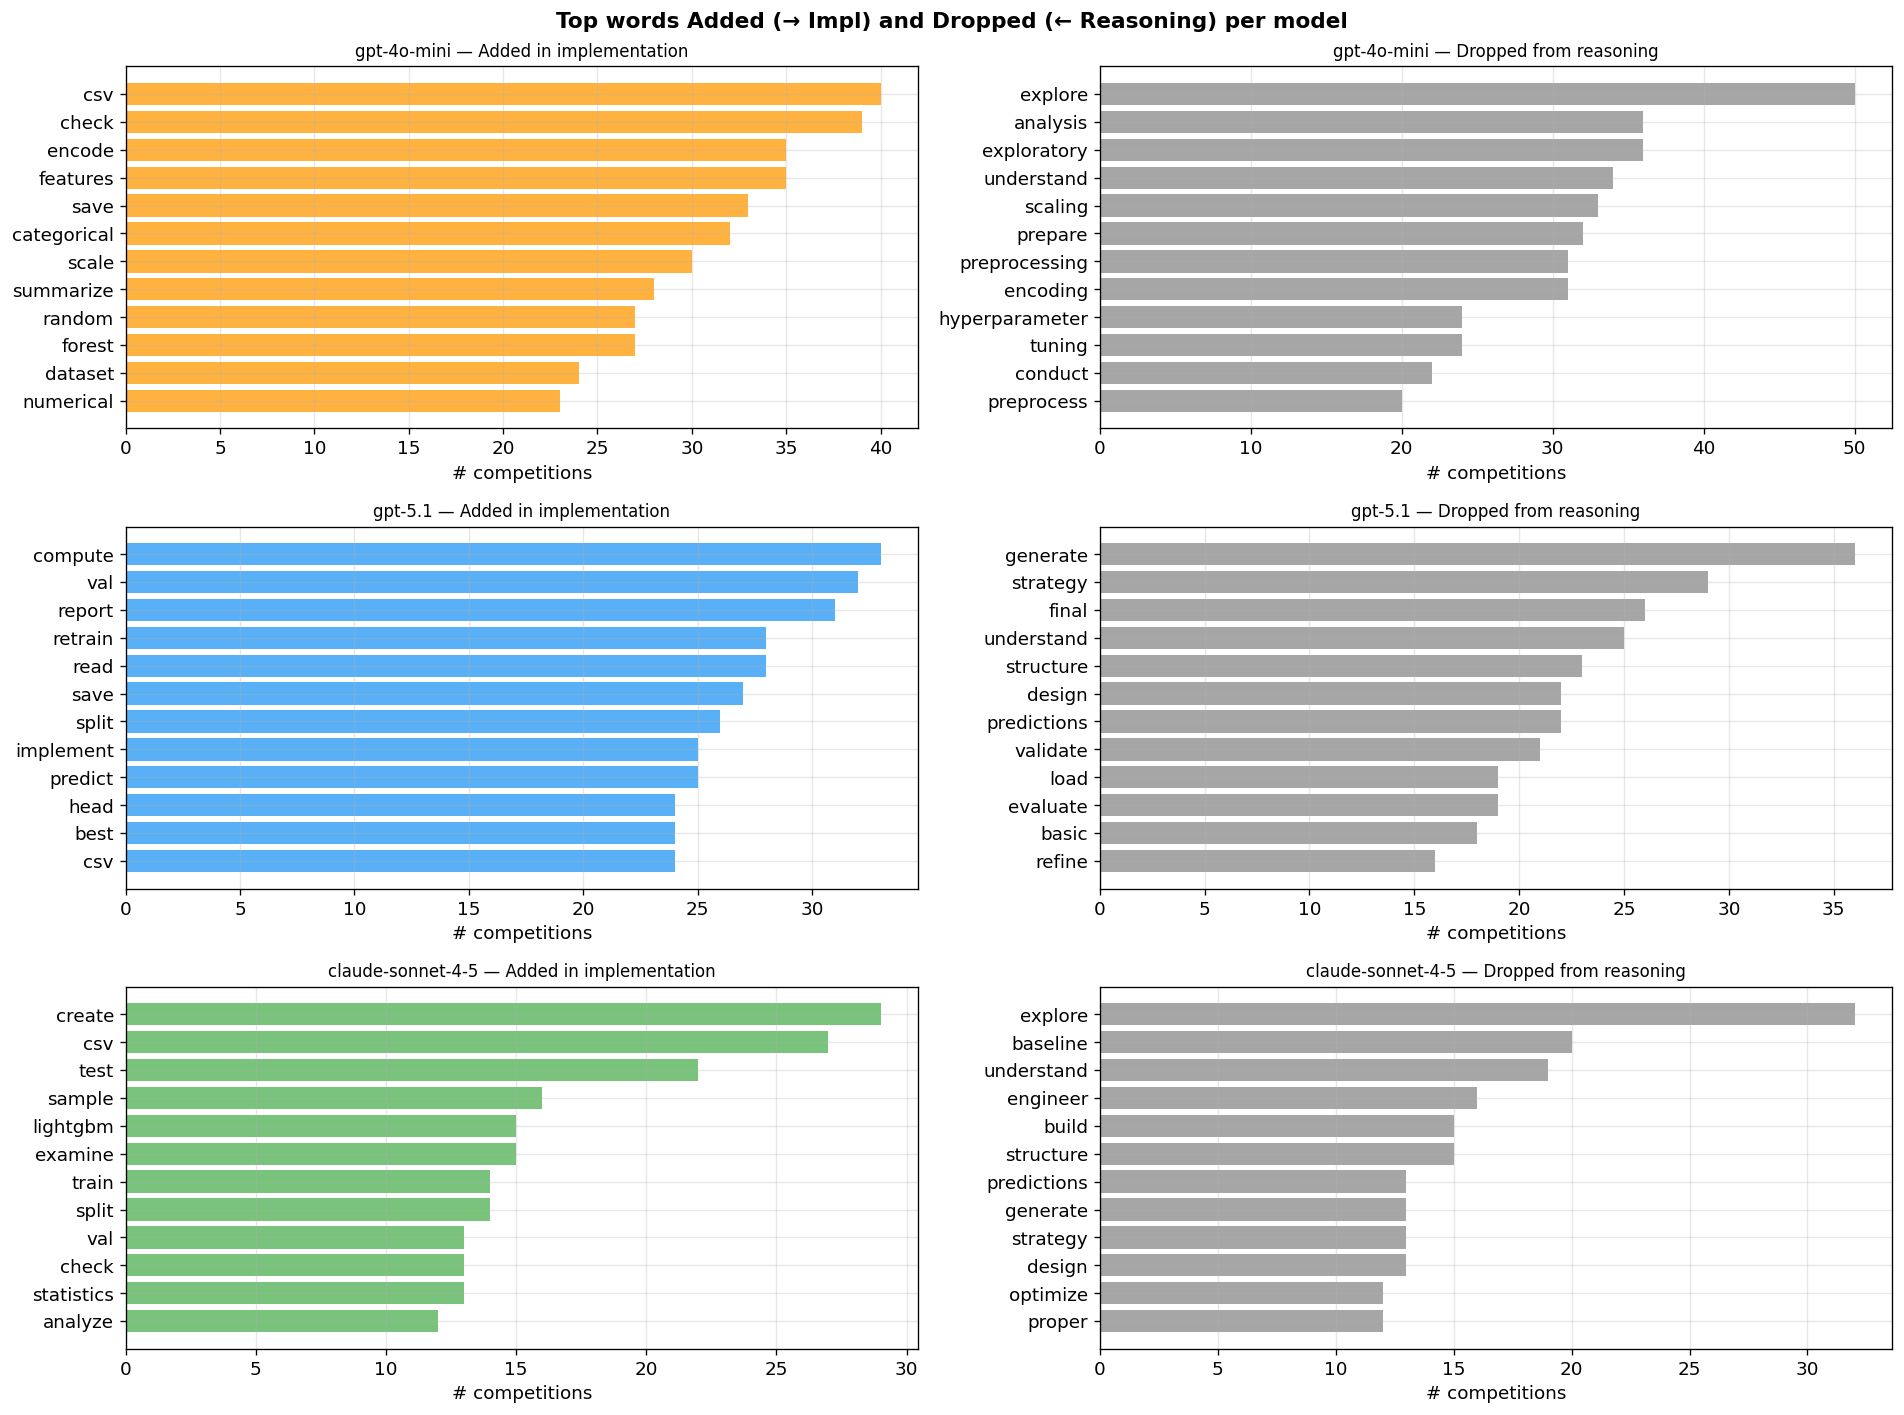

In [10]:
fig, axes = plt.subplots(len(MODEL_CONFIGS), 2,
                       figsize=(16, 4 * len(MODEL_CONFIGS)))
fig.suptitle("Top words Added (→ Impl) and Dropped (← Reasoning) per model",
             fontsize=13, fontweight="bold")

for row_i, model in enumerate(MODEL_CONFIGS):
    recs = [r for r in records if r["model"]==model and r["has_dag"]]
    added   = Counter()
    dropped = Counter()
    for r in recs:
        for w in r["i_kw"] - r["r_kw"]: added[w]   += 1
        for w in r["r_kw"] - r["i_kw"]: dropped[w] += 1

    color = MODEL_CONFIGS[model]["color"]

    for col_i, (ctr, label, clr) in enumerate([
        (added,   f"Added in implementation",    color),
        (dropped, f"Dropped from reasoning",     "#888888"),
    ]):
        ax    = axes[row_i, col_i] if len(MODEL_CONFIGS) > 1 else axes[col_i]
        top   = ctr.most_common(12)
        words = [w for w,_ in top][::-1]
        cnts  = [c for _,c in top][::-1]
        ax.barh(words, cnts, color=clr, alpha=0.75)
        ax.set_title(f"{model} — {label}", fontsize=10)
        ax.set_xlabel("# competitions")

plt.tight_layout()
plt.savefig(TASK_DIR / "dag_vocab_shift.png", bbox_inches="tight", dpi=150)
plt.show()


## 3 · Code-Following-Plan: Per-node Coverage
For each implementation node, does at least one keyword from its label appear anywhere in the generated code?

A high score here is **necessary but not sufficient** — it measures keyword presence, not semantic correctness.
The interesting signal is **where** in the plan coverage fails (start vs end) and which outcomes show partial coverage.


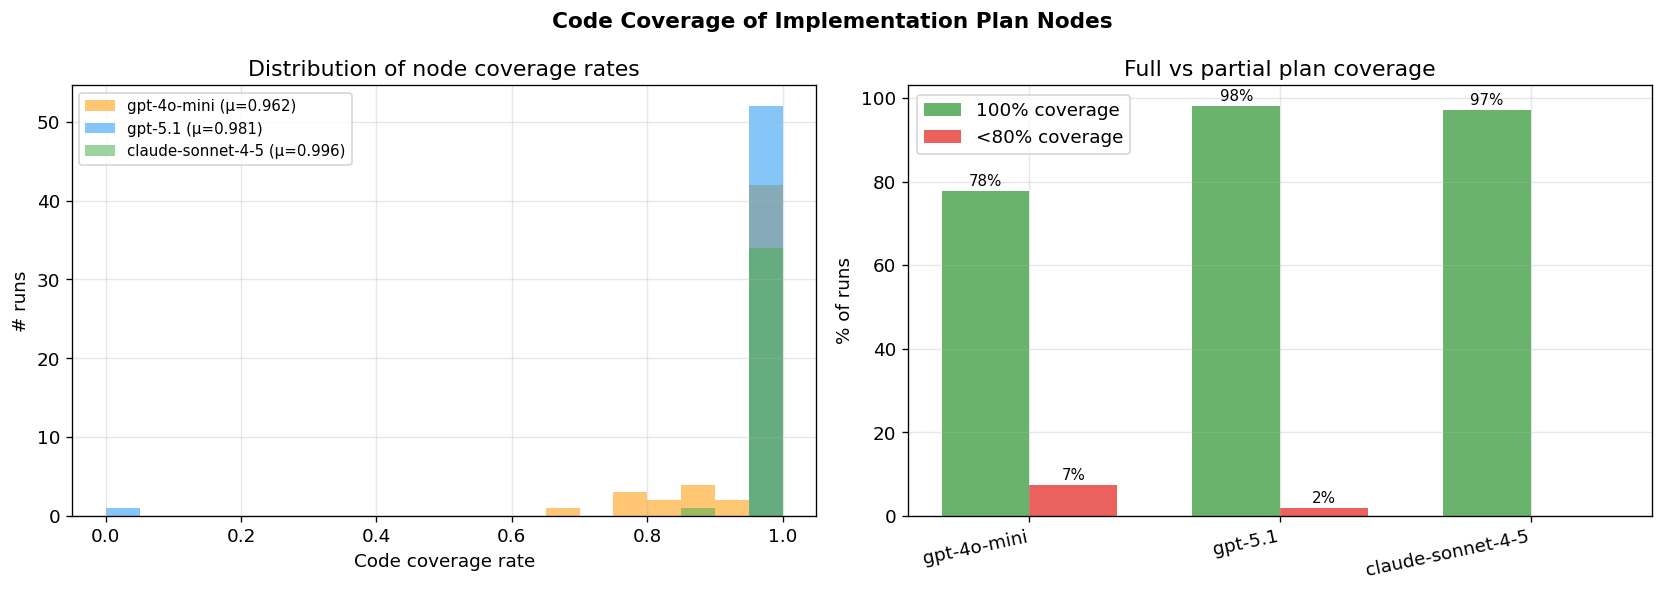

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Code Coverage of Implementation Plan Nodes", fontsize=13, fontweight="bold")

# Left: distribution of coverage rates
ax = axes[0]
for model, cfg in MODEL_CONFIGS.items():
    vals = df_dag[df_dag["model"]==model]["code_cov"].dropna().values
    if len(vals) == 0: continue
    ax.hist(vals, bins=20, range=(0,1), alpha=0.55,
            label=f"{model} (μ={vals.mean():.3f})", color=cfg["color"])
ax.set_xlabel("Code coverage rate")
ax.set_ylabel("# runs")
ax.set_title("Distribution of node coverage rates")
ax.legend(fontsize=9)

# Right: pct with 100% vs <80%
ax = axes[1]
model_list = list(MODEL_CONFIGS.keys())
x = np.arange(len(model_list))
w = 0.35
full_pcts  = []
low_pcts   = []
for m in model_list:
    vals = df_dag[df_dag["model"]==m]["code_cov"].dropna().values
    full_pcts.append(100 * sum(v == 1.0 for v in vals) / max(1, len(vals)))
    low_pcts.append( 100 * sum(v <  0.8 for v in vals) / max(1, len(vals)))

b1 = ax.bar(x - w/2, full_pcts, w, label="100% coverage", color="#43A047", alpha=0.8)
b2 = ax.bar(x + w/2, low_pcts,  w, label="<80% coverage", color="#E53935", alpha=0.8)
for bar, v in zip([*b1,*b2], full_pcts+low_pcts):
    if v > 1:
        ax.text(bar.get_x()+bar.get_width()/2, v+0.5,
                f"{v:.0f}%", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x)
ax.set_xticklabels(model_list, rotation=12, ha="right")
ax.set_ylabel("% of runs")
ax.set_title("Full vs partial plan coverage")
ax.legend()

plt.tight_layout()
plt.savefig(TASK_DIR / "dag_code_coverage.png", bbox_inches="tight", dpi=150)
plt.show()


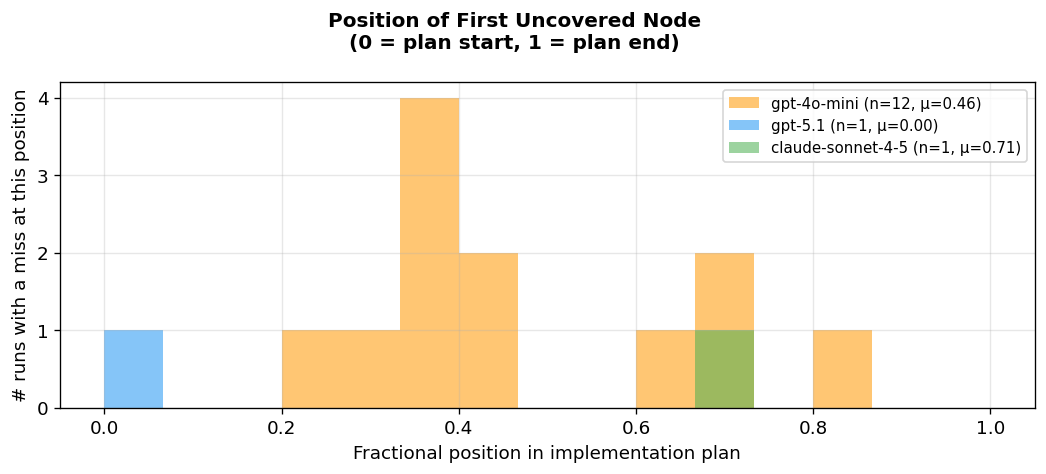


Interpretation:
  • Misses near 0  → model skips early EDA/inspection steps (often deliberate)
  • Misses near 1  → model fails to complete final submission/validation steps
  • Misses in mid  → plan diverges mid-execution (timeout, error, context loss)


In [12]:
# First-miss position: where in the plan does coverage first fail?
fig, ax = plt.subplots(figsize=(9, 4))
fig.suptitle("Position of First Uncovered Node\n(0 = plan start, 1 = plan end)",
             fontsize=12, fontweight="bold")

for model, cfg in MODEL_CONFIGS.items():
    vals = df_dag[df_dag["model"]==model]["first_miss"].dropna().values
    if len(vals) == 0: continue
    ax.hist(vals, bins=15, range=(0,1), alpha=0.55,
            label=f"{model} (n={len(vals)}, μ={vals.mean():.2f})", color=cfg["color"])

ax.set_xlabel("Fractional position in implementation plan")
ax.set_ylabel("# runs with a miss at this position")
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig(TASK_DIR / "dag_first_miss.png", bbox_inches="tight", dpi=150)
plt.show()

print("\nInterpretation:")
print("  • Misses near 0  → model skips early EDA/inspection steps (often deliberate)")
print("  • Misses near 1  → model fails to complete final submission/validation steps")
print("  • Misses in mid  → plan diverges mid-execution (timeout, error, context loss)")


## 4 · Inter-model Plan Divergence
On competitions where multiple models ran, how similar are their reasoning and implementation plans?

A **Jaccard of ~0.15–0.20** means models formulate fundamentally different plans for the same task.


In [13]:
# Build per-competition keyword sets for cross-model comparison
by_comp_r = defaultdict(dict)  # comp -> model -> r_kw
by_comp_i = defaultdict(dict)  # comp -> model -> i_kw

for r in records:
    if r["has_dag"]:
        by_comp_r[r["comp"]][r["model"]] = r["r_kw"]
        by_comp_i[r["comp"]][r["model"]] = r["i_kw"]

model_list = list(MODEL_CONFIGS.keys())
pairs      = [(a, b) for i, a in enumerate(model_list) for b in model_list[i+1:]]

cross_rows = []
for comp in by_comp_r:
    if len(by_comp_r[comp]) < 2:
        continue
    for m1, m2 in pairs:
        if m1 not in by_comp_r[comp] or m2 not in by_comp_r[comp]:
            continue
        rj = jaccard(by_comp_r[comp][m1], by_comp_r[comp][m2])
        ij = jaccard(by_comp_i[comp][m1], by_comp_i[comp][m2])
        cross_rows.append({"comp": comp, "m1": m1, "m2": m2,
                           "r_jaccard": rj, "i_jaccard": ij})

cross_df = pd.DataFrame(cross_rows)

print("=== Average cross-model plan similarity ===\n")
pivot_r = cross_df.groupby(["m1","m2"])["r_jaccard"].mean().reset_index()
pivot_i = cross_df.groupby(["m1","m2"])["i_jaccard"].mean().reset_index()
merged  = pivot_r.merge(pivot_i, on=["m1","m2"])
merged.columns = ["Model A","Model B","Avg R Jaccard","Avg I Jaccard"]
merged["n competitions"] = cross_df.groupby(["m1","m2"]).size().values
for col in ["Avg R Jaccard","Avg I Jaccard"]:
    merged[col] = merged[col].round(3)
display(merged)


=== Average cross-model plan similarity ===



,Model A,Model B,Avg R Jaccard,Avg I Jaccard,n competitions
0,gpt-4o-mini,claude-sonnet-4-5,0.198,0.191,35
1,gpt-4o-mini,gpt-5.1,0.148,0.135,53
2,gpt-5.1,claude-sonnet-4-5,0.190,0.205,34


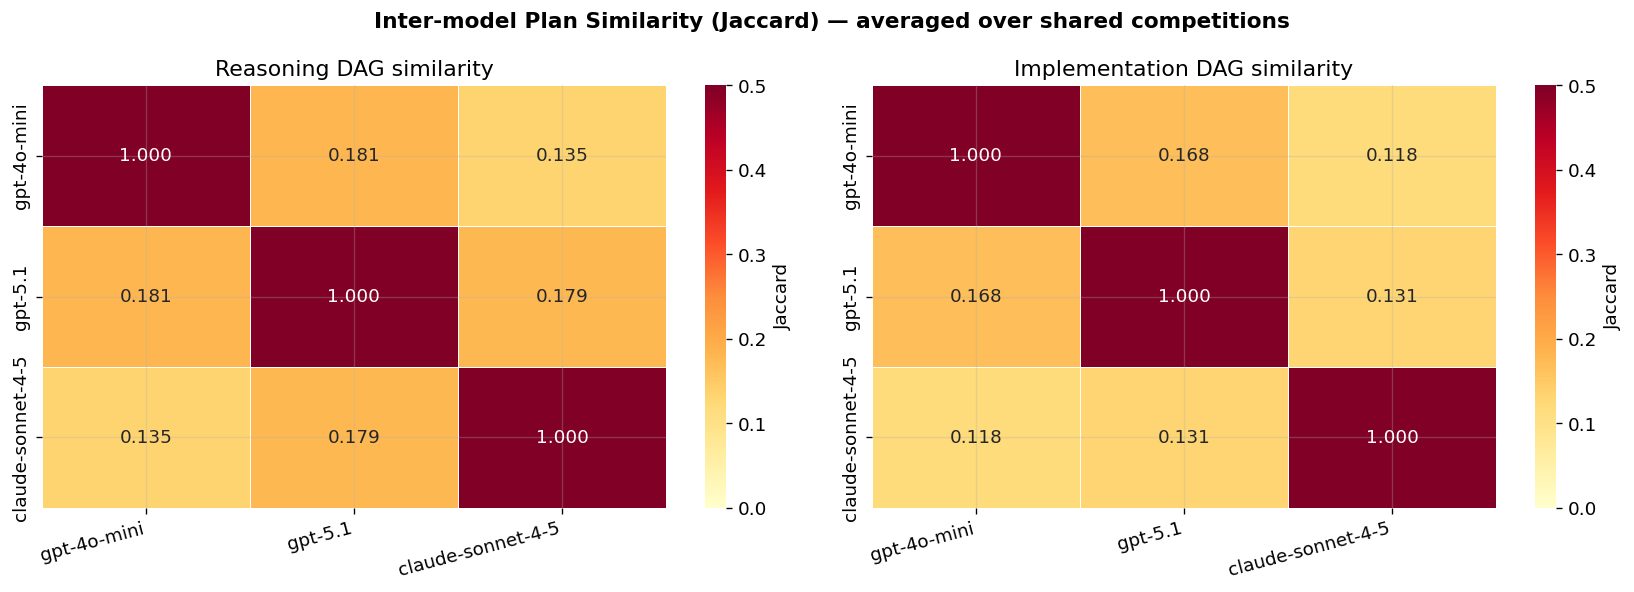

In [14]:
# Heatmap of pairwise similarities
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Inter-model Plan Similarity (Jaccard) — averaged over shared competitions",
             fontsize=13, fontweight="bold")

for ax, plan, title in zip(axes,
    ["r_jaccard", "i_jaccard"],
    ["Reasoning DAG similarity", "Implementation DAG similarity"]):

    mat = pd.DataFrame(index=model_list, columns=model_list, dtype=float)
    for m in model_list: mat.loc[m, m] = 1.0
    for _, row in cross_df.iterrows():
        mat.loc[row["m1"], row["m2"]] = row[plan]
        mat.loc[row["m2"], row["m1"]] = row[plan]

    sns.heatmap(mat.astype(float), ax=ax, annot=True, fmt=".3f",
                cmap="YlOrRd", vmin=0, vmax=0.5,
                linewidths=0.5, cbar_kws={"label": "Jaccard"})
    ax.set_title(title)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=15, ha="right")

plt.tight_layout()
plt.savefig(TASK_DIR / "dag_cross_model_similarity.png", bbox_inches="tight", dpi=150)
plt.show()


In [15]:
# Per-competition: all models' R→I Jaccard side by side (sorted by competition name)
shared_comps = sorted([c for c in by_comp_r if len(by_comp_r[c]) == len(MODEL_CONFIGS)])
print(f"Competitions with all {len(MODEL_CONFIGS)} models: {len(shared_comps)}")

if shared_comps:
    ri_table = []
    for comp in shared_comps:
        row = {"Competition": comp}
        for m in model_list:
            if m in by_comp_r[comp] and m in by_comp_i[comp]:
                row[f"{m} R→I"] = round(jaccard(by_comp_r[comp][m], by_comp_i[comp][m]), 3)
            else:
                row[f"{m} R→I"] = None
        # cross-model reasoning similarity
        if all(m in by_comp_r[comp] for m in model_list):
            pairs_j = [jaccard(by_comp_r[comp][m1], by_comp_r[comp][m2]) for m1,m2 in pairs]
            row["Avg cross-model R sim"] = round(sum(pairs_j)/len(pairs_j), 3)
        ri_table.append(row)

    ri_df = pd.DataFrame(ri_table).set_index("Competition")
    display(ri_df.sort_index())


Competitions with all 3 models: 34


,gpt-4o-mini R→I,gpt-5.1 R→I,claude-sonnet-4-5 R→I,Avg cross-model R sim
Competition,,,,
LANL-Earthquake-Prediction,0.342,0.267,0.128,0.156
ashrae-energy-prediction,0.314,0.289,0.190,0.187
career-con-2019,0.431,0.194,0.200,0.194
digit-recognizer,0.327,0.190,0.265,0.169
elo-merchant-category-recommendation,0.315,0.275,0.272,0.223
gendered-pronoun-resolution,0.292,0.239,0.185,0.206
geolifeclef-2024,0.393,0.252,0.375,0.174
home-credit-default-risk,0.340,0.225,0.241,0.231
humpback-whale-identification,0.407,0.271,0.309,0.118


## 5 · Interpretation Guide

### Reading R→I Jaccard

| Value | Meaning |
|---|---|
| **> 0.35** | Model copies reasoning into implementation verbatim. Plans are generic templates, not competition-specific. Red flag: check if both DAGs say the same thing. |
| **0.20 – 0.35** | Moderate specialisation. Some vocabulary is preserved but new domain-specific steps are introduced. |
| **< 0.20** | High specialisation. Implementation plan is a genuine technical refinement of the abstract reasoning. Healthy sign for complex competitions. |

### Reading Code Coverage

| Value | Meaning |
|---|---|
| **≈ 1.0** | All planned steps have at least one keyword present in generated code. Note: this is a *necessary* condition, not sufficient. A keyword can appear in an error message too. |
| **0.8 – 1.0** | Most plan steps are addressed in code. |
| **< 0.8** | Significant plan–code drift. The model wrote a plan it did not follow, or execution was cut short. |

### Reading First Miss Position

| Value | Meaning |
|---|---|
| **≈ 0** | Misses on early nodes. Often deliberate skips of EDA/inspection steps in favour of going straight to modelling. Usually benign. |
| **≈ 0.5** | Misses in the middle. Suggests execution breakdown mid-run (timeout, server error, context overflow). |
| **≈ 1** | Misses on final nodes (submission writing, format validation). Model completes all modelling steps but fails to produce a submission. Critical for benchmark completion rate. |

### Reading Cross-model Similarity

- Values of **0.10 – 0.20** are typical when models use different vocabularies and strategies.
- Values above **0.30** on the same competition suggest the models are following a similar template — interesting to investigate whether this is because the task is narrow or because both models are defaulting to the same boilerplate.


## 6 · Spot-check: Show individual run plans

In [16]:
# Set model and competition to inspect a specific run's DAG plans
INSPECT_MODEL = list(MODEL_CONFIGS.keys())[0]
INSPECT_COMP  = None   # None = pick the first available

recs_model = [r for r in records if r["model"]==INSPECT_MODEL and r["has_dag"]]
if not recs_model:
    print(f"No DAG records found for {INSPECT_MODEL}")
else:
    rec = next((r for r in recs_model if INSPECT_COMP and INSPECT_COMP in r["comp"]),
               recs_model[0])
    print(f"Model:       {rec['model']}")
    print(f"Competition: {rec['comp']}")
    print(f"Outcome:     {rec['outcome']}")
    print(f"R→I Jaccard: {rec.get('ri_jaccard', 'N/A'):.3f}")
    print(f"Code cov:    {rec.get('code_cov', 'N/A'):.3f}")
    print()
    print("REASONING nodes:")
    for i, lbl in enumerate(rec.get("r_lbls", []), 1):
        print(f"  {i}. {lbl}")
    print()
    print("IMPLEMENTATION nodes:")
    for i, lbl in enumerate(rec.get("i_lbls", []), 1):
        r_kw_set = rec.get("r_kw", set())
        node_kw  = set(w for w in re.findall(r"[a-z][a-z0-9]+", lbl)
                       if w not in STOP_WORDS and len(w)>2)
        in_code  = bool(node_kw & set(re.findall(r"[a-z][a-z0-9]+", rec["all_code"])))
        overlap  = node_kw & r_kw_set
        tag = "✓" if in_code else "✗"
        new = " [NEW]" if not overlap else ""
        print(f"  {i}. [{tag}] {lbl}{new}")
    print()
    print("  ✓ = keyword found in code   ✗ = not found   [NEW] = not in reasoning")


Model:       gpt-4o-mini
Competition: LANL-Earthquake-Prediction
Outcome:     no_submit
R→I Jaccard: 0.342
Code cov:    1.000

REASONING nodes:
  1. load and explore training and test datasets.
  2. perform data preprocessing and exploratory analysis.
  3. select and train baseline models.
  4. evaluate models and perform hyperparameter tuning.
  5. generate predictions for the test data.
  6. validate submission format.

IMPLEMENTATION nodes:
  1. [✓] load training and test datasets using pandas.
  2. [✓] check for missing values and basic statistics. [NEW]
  3. [✓] perform feature engineering on acoustic_data.
  4. [✓] train a baseline model (e.g., random forest) on the training data.
  5. [✓] evaluate model performance using cross-validation.
  6. [✓] generate predictions for the test dataset.
  7. [✓] validate the submission format against the sample submission.

  ✓ = keyword found in code   ✗ = not found   [NEW] = not in reasoning
